# Задача 6. Затухание света

Фотон, прошедший в сцинтилляторе путь $l$, не поглощается с вероятностью $e^{-l/L}$, $L = 8$ м. В `Detector` добавлен параметр `attenuation_length` (по умолчанию $\infty$ — без затухания):

- `path_length(o, n)` — путь до стенки $t = -(\vec o\cdot\vec n) + \sqrt{(\vec o\cdot\vec n)^2 - o^2 + R^2}$ (тот же корень, что в задаче 3);
- `survives(t)` — розыгрыш: фотон выживает, если $u < e^{-t/L}$, $u \sim U(0,1)$;
- `trace` помечает поглощённые фотоны как $-1$.

Путь до катода считаем равным пути до сферы: катод вписан, разница не больше $R - \sqrt{R^2 - r^2} \approx 2.5$ мм $\ll L$.

Ожидание: доля фотонов на ФЭУ $k$ — $\frac{\Omega_k}{4\pi} e^{-d_k/L}$, где $\Omega_k \approx \pi r^2\cos\psi_k/d_k^2$ (функция `expected_fraction`, проверена сравнением с трассировкой).

In [1]:
import sys
sys.path.insert(0, '../src')   # код проекта
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector
from source import Source
from simulation import simulate_charge, expected_fraction

L_att = 8.0
det_att = Detector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=L_att, rng=6)
det_free = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=60)
src = Source(Y=10_000, rng=600)

E, n_events = 1.0, 1000
z_values = np.array([-1.8, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 1.8])

In [2]:
Q_att, Q_free = {}, {}
for z in z_values:
    o = (0, 0, z)
    Q_att[z] = simulate_charge(det_att, src, E, origin=o, n_events=n_events).sum(axis=1)
    Q_free[z] = simulate_charge(det_free, src, E, origin=o, n_events=n_events).sum(axis=1)

def summary(Q, det):
    m = np.array([Q[z].mean() for z in z_values])
    s = np.array([Q[z].std() for z in z_values])
    ex = np.array([det.a * src.Y * E * expected_fraction(det, (0, 0, z)).sum() for z in z_values])
    return m, s, ex

m_a, s_a, ex_a = summary(Q_att, det_att)
m_f, s_f, ex_f = summary(Q_free, det_free)
print("   z, м | без затухания: <Q>  ожид.  σ/<Q> | с затуханием: <Q>  ожид.  σ/<Q> | отношение")
for i, z in enumerate(z_values):
    print(f"{z:7.1f} | {m_f[i]:18.1f} {ex_f[i]:6.1f} {s_f[i]/m_f[i]:6.3f} |"
          f" {m_a[i]:17.1f} {ex_a[i]:6.1f} {s_a[i]/m_a[i]:6.3f} | {m_a[i]/m_f[i]:.3f}")
print(f"\ne^(-R/L) = {np.exp(-det_att.R/L_att):.3f}")

   z, м | без затухания: <Q>  ожид.  σ/<Q> | с затуханием: <Q>  ожид.  σ/<Q> | отношение
   -1.8 |              103.3  101.4  0.123 |              85.7   84.1  0.132 | 0.830
   -1.5 |              122.3  122.6  0.113 |             101.0  101.0  0.119 | 0.826
   -1.0 |              124.4  125.2  0.105 |              98.7   99.9  0.121 | 0.794
   -0.5 |              125.2  125.3  0.110 |              98.1   98.2  0.125 | 0.784
    0.0 |              125.4  125.3  0.107 |              98.4   97.6  0.123 | 0.784
    0.5 |              126.0  125.3  0.110 |              97.8   98.2  0.130 | 0.776
    1.0 |              125.7  125.2  0.115 |              99.9   99.9  0.122 | 0.795
    1.5 |              122.3  122.6  0.112 |             101.4  101.0  0.128 | 0.829
    1.8 |              102.3  101.4  0.120 |              85.5   84.1  0.131 | 0.836

e^(-R/L) = 0.779


## Распределения заряда

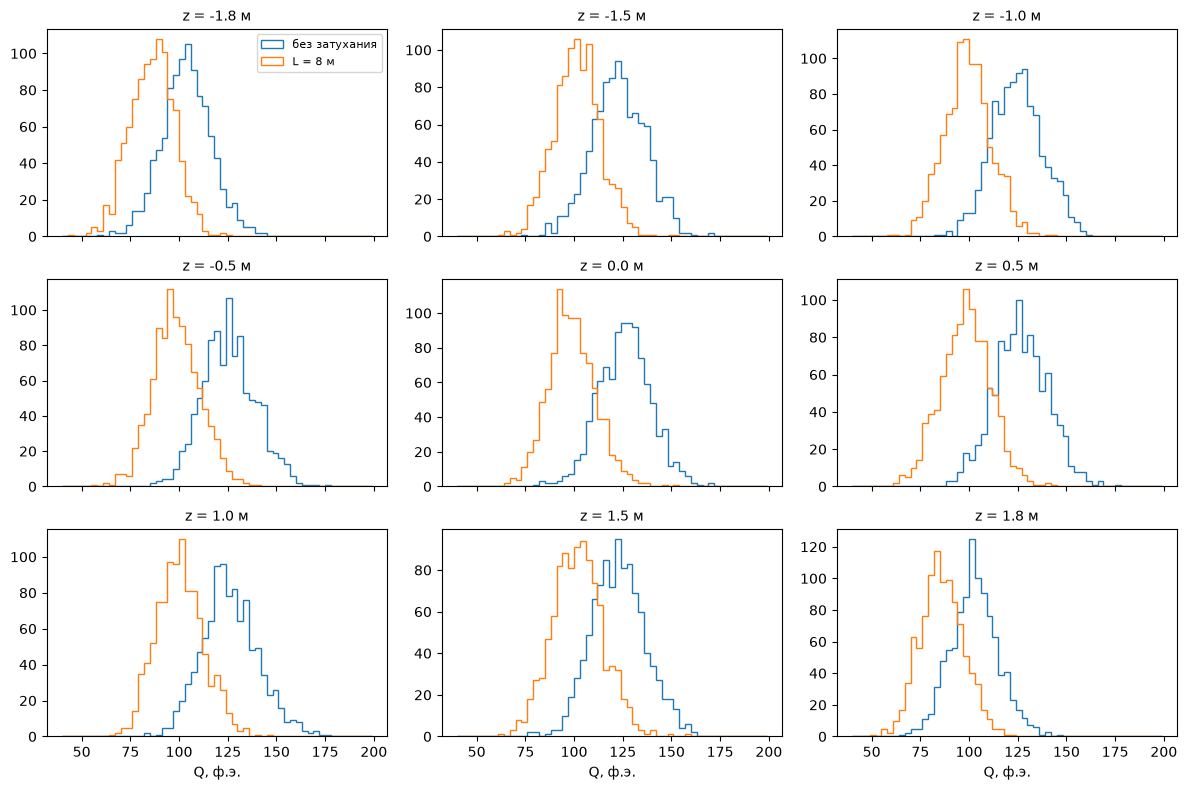

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
bins = np.arange(40, 200, 3)
for ax, z in zip(axes.flat, z_values):
    ax.hist(Q_free[z], bins=bins, histtype='step', label='без затухания')
    ax.hist(Q_att[z], bins=bins, histtype='step', label=f'L = {L_att:g} м')
    ax.set_title(f'z = {z} м', fontsize=10)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('Q, ф.э.')
plt.tight_layout(); plt.show()

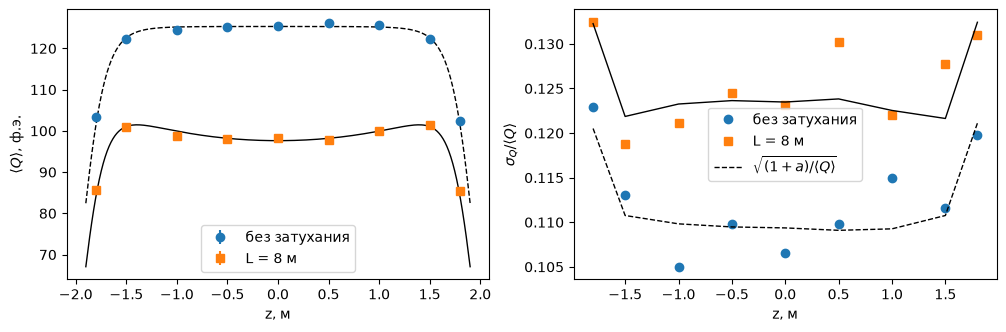

In [4]:
err = lambda s: s / np.sqrt(n_events)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].errorbar(z_values, m_f, err(s_f), fmt='o', label='без затухания')
ax[0].errorbar(z_values, m_a, err(s_a), fmt='s', label=f'L = {L_att:g} м')
zg = np.linspace(-1.9, 1.9, 200)
for det, st in ((det_free, '--'), (det_att, '-')):
    ax[0].plot(zg, [det.a * src.Y * E * expected_fraction(det, (0, 0, z)).sum() for z in zg], 'k' + st, lw=1)
ax[0].set_xlabel('z, м'); ax[0].set_ylabel(r'$\langle Q\rangle$, ф.э.'); ax[0].legend()

ax[1].plot(z_values, s_f / m_f, 'o', label='без затухания')
ax[1].plot(z_values, s_a / m_a, 's', label=f'L = {L_att:g} м')
ax[1].plot(z_values, np.sqrt((1 + det_free.a) / m_f), 'k--', lw=1, label=r'$\sqrt{(1+a)/\langle Q\rangle}$')
ax[1].plot(z_values, np.sqrt((1 + det_att.a) / m_a), 'k-', lw=1)
ax[1].set_xlabel('z, м'); ax[1].set_ylabel(r'$\sigma_Q/\langle Q\rangle$'); ax[1].legend()
plt.show()

## Почему потери на затухание уменьшаются к краю

С затуханием каждый ФЭУ дополнительно ослаблен множителем $e^{-d_k/L}$. У источника вблизи стенки примерно половина света уходит в ближнюю стенку, поэтому средний путь фотона и потери **уменьшаются** при удалении от центра.

Для сплошного покрытия средний путь до стенки от точки на расстоянии $\rho$ от центра: $\langle l\rangle = \frac{1}{2}\int_{-1}^{1}\left(-\rho\mu + \sqrt{\rho^2\mu^2 - \rho^2 + R^2}\right)d\mu$; проверим это численно.

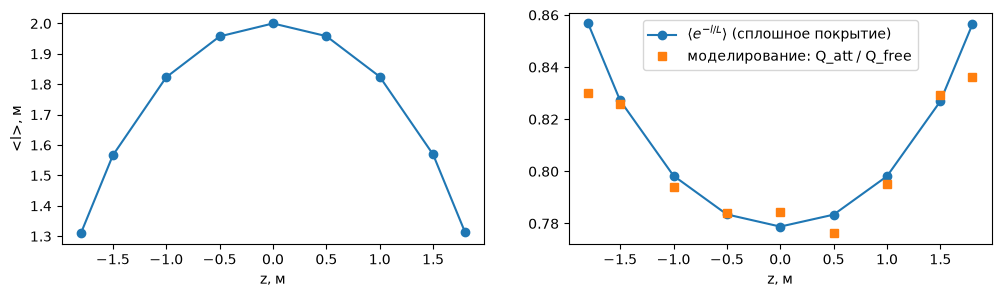

In [5]:
n_dirs = np.random.default_rng(0).normal(size=(1_000_000, 3))
n_dirs /= np.linalg.norm(n_dirs, axis=1, keepdims=True)
mean_path = [det_free.path_length(np.array([0, 0, z]), n_dirs).mean() for z in z_values]
mean_surv = [np.exp(-det_free.path_length(np.array([0, 0, z]), n_dirs) / L_att).mean() for z in z_values]
plt.figure(figsize=(12, 3))
plt.subplot(1, 2, 1); plt.plot(z_values, mean_path, 'o-'); plt.xlabel('z, м'); plt.ylabel('<l>, м')
plt.subplot(1, 2, 2)
plt.plot(z_values, mean_surv, 'o-', label=r'$\langle e^{-l/L}\rangle$ (сплошное покрытие)')
plt.plot(z_values, m_a / m_f, 's', label='моделирование: Q_att / Q_free')
plt.xlabel('z, м'); plt.legend(); plt.show()

**Выводы.**
- В центре все фотоны проходят ровно $R = 2$ м, заряд уменьшается в $e^{-R/L} = e^{-0.25} \approx 0.78$ раза (моделирование: $0.784 \pm 0.004$), относительная ширина растёт как $1/\sqrt{\langle Q\rangle}$ — примерно на 13%.
- Доля выживших фотонов $Q_{att}/Q_{free}$ растёт от центра к краю: 0.78 при $z=0$ и ≈0.83 при $|z| = 1.5$–$1.8$ м. До $|z| = 1.5$ м это согласуется с $\langle e^{-l/L}\rangle$ для сплошного покрытия, а при $|z| = 1.8$ м сплошное покрытие дало бы 0.857: там сказывается дискретность ФЭУ. Т.е. затухание делает отклик детектора **неоднородным** даже там, где без затухания он однороден: при $|z| \le 1$ м без затухания ожидаемый $\langle Q\rangle$ меняется лишь на 0.1%, а с затуханием на ≈2%.
- Вблизи стенки ($|z| = 1.8$ м, 20 см до поверхности) заряд падает на ≈18% **уже без затухания**. Это эффект дискретности ФЭУ, а не затухания: половина света попадает на малый участок ближней стенки, а ближайший ФЭУ расположен в ≈45 см от полюса (у спирали Фибоначчи нет ФЭУ точно на оси). Вывод теоремы Гаусса о постоянстве заряда справедлив только для сплошного покрытия. Столбец «ожид.» здесь занижен примерно на 1%: это приближение малого диска, которое у стенки менее точно (трассировка с $2\cdot10^7$ лучей даёт долю фотонов 0.02050 против 0.02029).
- Форма каждого распределения остаётся составным Пуассоном: $\sigma_Q/\langle Q\rangle \approx \sqrt{(1+a)/\langle Q\rangle}$ — затухание лишь уменьшает число зарегистрированных фотонов.
- Неоднородность отклика (от затухания и от геометрии) без поправки на положение вершины ухудшает энергетическое разрешение: одна и та же энергия даёт разный заряд в разных точках детектора.